In [ ]:
import yfinance as yf
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from scipy.optimize import minimize

In [ ]:
# Parsisiunciam duomenis

ticker1='ORCL'
tickers2=['ORCL','JPM']
tickers3=['ORCL','JPM','XOM','WMT']

start1='2024-01-01'
end1='2026-10-28'

start2='2023-01-01'
end2='2026-10-28'

start3='2022-01-01'
end3='2026-10-28'

df1=yf.download(ticker1,start=start1,end=end1,auto_adjust=True)
df2=yf.download(tickers2,start=start2,end=end2,auto_adjust=True)
df3=yf.download(tickers3,start=start3,end=end3,auto_adjust=True)


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  2 of 2 completed
[*********************100%***********************]  4 of 4 completed


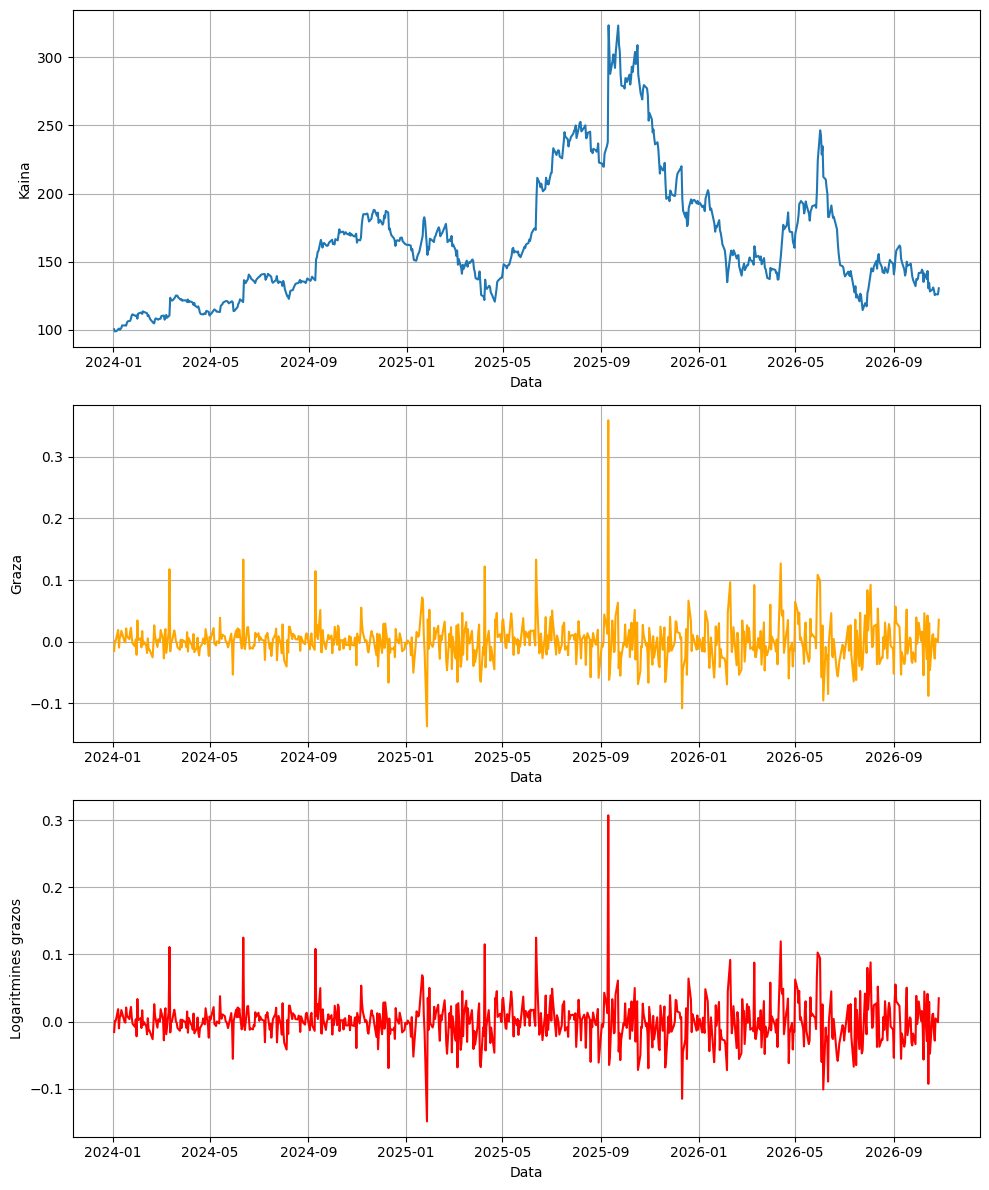

In [ ]:
# Oracle akcijos kainos, paprastuju grazu ir logaritminiu grazu grafikai

df1=df1.dropna()
price=df1['Close']
simple_returns=price.pct_change()
log_returns=np.log(1+simple_returns)

fig,ax=plt.subplots(3,1,figsize=(10,12))
ax[0].plot(price.index,price)
ax[0].set_xlabel('Data')
ax[0].set_ylabel('Kaina')
ax[0].grid(True)
ax[1].plot(price.index,simple_returns,color='orange')
ax[1].set_xlabel('Data')
ax[1].set_ylabel('Graza')
ax[1].grid(True)
ax[2].plot(price.index,log_returns,color='red')
ax[2].set_xlabel('Data')
ax[2].set_ylabel('Logaritmines grazos')
ax[2].grid(True)


plt.tight_layout()
plt.show()

In [ ]:
# Tikriname hipotezes
# H0: grazos pasiskirsciusios pagal normaluji desni
# H1: grazos nera pasiskirsciusios pagal normaluji desni

shapiro_test=stats.shapiro(simple_returns.dropna())
p_value=shapiro_test.pvalue
test_statistic=shapiro_test.statistic

reiksmingumo_lygmuo=0.05

if p_value<reiksmingumo_lygmuo:
  print("Grazos nera pasiskirsciusios pagal normaluji desni")
else:
  print("Grazos yra pasiskirsciusios pagal normaluji desni")


Grazos nera pasiskirsciusios pagal normaluji desni


In [ ]:
# Sharpe ratio = (mu-rf)/sigma

# Tiketina graza vertinama imties vidurkiu
mu=simple_returns.mean()

# Standartinis nuokryptis vertinamas imties standartiniu nuokrypiu
sigma=simple_returns.std()

# Nerizikinga palukanu norma (risk-free rate), kuri bus naudojama skaiciavimams yra JAV izdo vekseliu dienos palukanu norma ekvivalenti metinei pagal lapkrio 13d duomenis
# ekvivalenti norma skaiciuojama is lygties (1+j)^252=1+i, 252 - kiek dienu per metus vyksta finansiniai sandoriai
rf_met=4.23
rf=(1+4.23/100)**(1/252)-1

# Dieninis Sharpe ratio

sharpe_dieninis=(mu-rf)/sigma

# Metinis Sharpe ratio

sharpe_metinis=sharpe_dieninis*252**(0.5)


# Sortino ratio skaiciuojamas, kaip Sortino=(mu-T)/DD, kur mu - akcijos tiketina graza, T - minimali priimtina graza (daznai T=0 arba T=rf), DD - grazu vidutinis kvadratinis
# nuokrypis nuo T, kurios yra mazesnes nei T

T=0
mu_s=mu-T
grazos_nep=simple_returns[simple_returns<T]-T
disp = (grazos_nep ** 2).sum() / len(simple_returns)
dd = np.sqrt(disp)

# Dieninis Sortino

sortino_d=mu_s/dd

# Metinis Sortino

sortino_m=sortino_d*252**(0.5)

print(f"Dieninis Sharpe koeficientas yra {sharpe_dieninis.item()}")
print(f"Metinis Sharpe koeficientas yra {sharpe_metinis.item()}")
print(f"Dieninis Sortino koeficientas yra {sortino_d.item()}")
print(f"Metinis Sortino koeficientas yra {sortino_m.item()}")

# Sharpe ratio parodo kiek grazos (atemus is jos risk-free rate) tenka vienam rizikos vienetui
# Sortino ratio taip pat parodo kiek grazos tenka vienam rizikos vienetui, bet rizika skaiciuojama tik ten, kur portfelis patyre nuostoli


Dieninis Sharpe koeficientas yra 0.022034364947422447
Metinis Sharpe koeficientas yra 0.3497846996887116
Dieninis Sortino koeficientas yra 0.04404346335317566
Metinis Sortino koeficientas yra 0.6991683054629385


Minimalios rizikos portfelis gaunamas investuojant 85.97% i JP Morgan ir 14.03% i ORACLE 
Maksimalaus Sharpe ratio portfelis gaunamas investuojant 90.27% i JP Morgan ir 9.73% i ORACLE
Akciju kainu koreliacija yra 0.6884386406950307
Akciju grazu koreliacija yra 0.17440703634202329


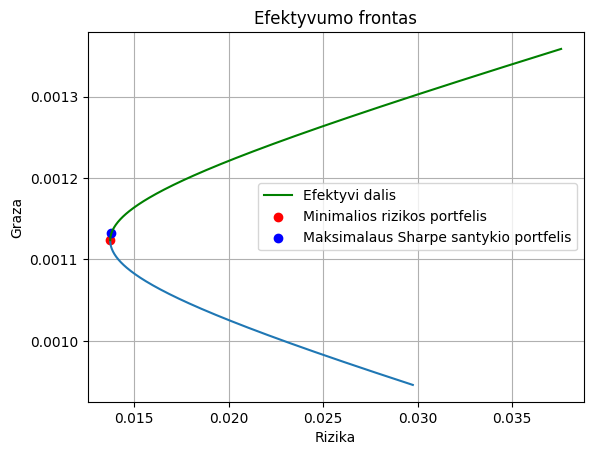

In [ ]:
jpm_price=df2['Close']['JPM']
orcl_price=df2['Close']['ORCL']

jpm_grazos=jpm_price.pct_change()
jpm_grazos=jpm_grazos.dropna()
orcl_grazos=orcl_price.pct_change()
orcl_grazos=orcl_grazos.dropna()

akciju_kainu_koreliacija=np.corrcoef(jpm_price,orcl_price)
akciju_kainu_koreliacija=akciju_kainu_koreliacija[0,1].item()

akciju_grazu_koreliacija=np.corrcoef(jpm_grazos,orcl_grazos)
akciju_grazu_koreliacija=akciju_grazu_koreliacija[0,1].item()

mu1=jpm_grazos.mean()
mu2=orcl_grazos.mean()

o1=jpm_grazos.std()
o2=orcl_grazos.std()

kovariacija=np.cov(jpm_grazos,orcl_grazos)[0,1]

min_rizikos_svoris=(o2**2-kovariacija)/(o1**2+o2**2-2*kovariacija)
kitas_svoris=1-min_rizikos_svoris

minimali_rizika=np.sqrt(min_rizikos_svoris**2*o1**2+kitas_svoris**2*o2**2+2*min_rizikos_svoris*kitas_svoris*kovariacija)
tiketina_graza=min_rizikos_svoris*mu1+kitas_svoris*mu2

max_sharpe_svoris=((mu1-rf)*o2**2-(mu2-rf)*kovariacija)/(((mu1-rf)*(o2**2-kovariacija))+(mu2-rf)*(o1**2-kovariacija))
kitas_svoris2=1-max_sharpe_svoris

max_sharpe_rizika=np.sqrt(max_sharpe_svoris**2*o1**2+kitas_svoris2**2*o2**2+2*max_sharpe_svoris*kitas_svoris2*kovariacija)
max_sharpe_tiketina_graza=max_sharpe_svoris*mu1+kitas_svoris2*mu2

def portfelis(w,o1,o2,mu1,mu2,kovariacija):
  koordinates=[]
  sigma_kvad=w**2*o1**2+(1-w)**2*o2**2+2*w*(1-w)*kovariacija
  sigma=np.sqrt(sigma_kvad)
  mu=w*mu1+(1-w)*mu2
  koordinates.append(sigma)
  koordinates.append(mu)
  return koordinates

sugeneruoti_svoriai=np.linspace(0,2,500)

sigma=[]
sigma_e=[]
mu=[]
mu_e=[]

for w in sugeneruoti_svoriai:
  koordinates=portfelis(w,o1,o2,mu1,mu2,kovariacija)
  if (mu1 < mu2 and w < min_rizikos_svoris) or (mu1 > mu2 and w > min_rizikos_svoris):
    mu_e.append(koordinates[1])
    sigma_e.append(koordinates[0])
  else:
    mu.append(koordinates[1])
    sigma.append(koordinates[0])


plt.plot(sigma,mu)
plt.plot(sigma_e,mu_e,color='green',label="Efektyvi dalis")
plt.scatter(minimali_rizika,tiketina_graza,color='red',label='Minimalios rizikos portfelis')
plt.scatter(max_sharpe_rizika,max_sharpe_tiketina_graza,color='blue',label='Maksimalaus Sharpe santykio portfelis')
plt.xlabel("Rizika")
plt.ylabel("Graza")
plt.title("Efektyvumo frontas")
plt.legend()
plt.grid()

print(f"Minimalios rizikos portfelis gaunamas investuojant {(min_rizikos_svoris*100).round(2)}% i JP Morgan ir {(kitas_svoris*100).round(2)}% i ORACLE ")
print(f"Maksimalaus Sharpe ratio portfelis gaunamas investuojant {(max_sharpe_svoris*100).round(2)}% i JP Morgan ir {(kitas_svoris2*100).round(2)}% i ORACLE")
print(f"Akciju kainu koreliacija yra {akciju_kainu_koreliacija}")
print(f"Akciju grazu koreliacija yra {akciju_grazu_koreliacija}")


In [ ]:
def MVP(sigma,n):
  vienetai=np.ones((1,n))
  return (np.linalg.inv(sigma) @ vienetai.T) / (vienetai @ np.linalg.inv(sigma) @ vienetai.T)

def MSR(mu,sigma,n,rf):
  vienetai=np.ones((1,n))
  return (np.linalg.inv(sigma) @ (mu-rf * vienetai).T)/(vienetai @ np.linalg.inv(sigma) @ (mu-rf * vienetai).T)

def fiksuota_graza(sigma,mu,mu0,n):
  sigma_inv=np.linalg.inv(sigma)
  vienetai=np.ones((1,n))
  a=np.hstack([sigma_inv @ mu.T,sigma_inv @ vienetai.T])
  mat=np.block([[mu @ sigma_inv @ mu.T,mu @ sigma_inv @ vienetai.T],[vienetai @ sigma_inv @ mu.T,vienetai @ sigma_inv @ vienetai.T]])
  b=np.linalg.inv(mat)
  c=np.array([[mu0],[1]])
  return a @ b @ c


def Sortino(b,R,T):
  '''
  Sortino santykis skaiciuojamas, kaip Sortino=(mu-T)/DD, kur T - minimali priimtina graza (daznai T=0 arba T=rf), DD - grazu vidutinis kvadratinis
  nuokrypis nuo T, kurios yra mazesnes nei T
  '''
  b=np.reshape(b,(1,-1))
  portfelio_grazos=R @ b.T
  nuokrypiai = portfelio_grazos[portfelio_grazos<T] - T
  dd=np.sqrt((nuokrypiai**2).sum()/len(portfelio_grazos))
  return (portfelio_grazos.mean()-T)/dd


def MSOR(R,T):
  n=R.shape[1]
  def tikslas(b):
    s=Sortino(b,R,T)
    return -s
  ribojimas={'type':'eq','fun':lambda b: b.sum()-1}
  b0=np.ones(n)/n
  res=minimize(tikslas,b0,method='SLSQP',constraints=ribojimas)
  return res.x.reshape(1,-1)

def graza(b,mu):
  return mu @ b.T

def rizika(b,sigma):
  return np.sqrt(b @ sigma @ b.T)

sigma=df3['Close'].pct_change().cov()

# Grazu vektorius
mu=np.array([[df3['Close']['JPM'].pct_change().mean(),df3['Close']['ORCL'].pct_change().mean(),df3['Close']['WMT'].pct_change().mean(),df3['Close']['XOM'].pct_change().mean()]])

min_rizikos_portfelis=MVP(sigma,len(sigma[sigma.columns[0]])).T
min_graza=graza(min_rizikos_portfelis,mu)
min_rizika=rizika(min_rizikos_portfelis,sigma)

max_sharpe_portfelis=MSR(mu,sigma,len(sigma[sigma.columns[0]]),rf).T
max_sharpe_graza=graza(max_sharpe_portfelis,mu)
max_sharpe_rizika=rizika(max_sharpe_portfelis,sigma)

max_sortino_portfelis=MSOR(df3['Close'].pct_change(),0)
max_sortino_graza=graza(max_sortino_portfelis,mu)
max_sortino_rizika=rizika(max_sortino_portfelis,sigma)

fiksuotos_grazos_portfelis=fiksuota_graza(sigma,mu,0.2/252,len(sigma[sigma.columns[0]])).T
fiksuotos_grazos_tiketina_graza=graza(fiksuotos_grazos_portfelis,mu)
fiksuotos_grazos_rizika=rizika(fiksuotos_grazos_portfelis,sigma)


print(f"Minimalios rizikos portfelis yra gaunasm is svoriu {(min_rizikos_portfelis[0][0]*100).round(2)}% i JPM, {(min_rizikos_portfelis[0][1]*100).round(2)}% i ORACLE,{(min_rizikos_portfelis[0][2]*100).round(2)}% i WMT,{(min_rizikos_portfelis[0][3]*100).round(2)}% i XOM")
print(f"Minimalios rizikos portfelio graza yra {(min_graza[0][0]*100).round(2)}%")
print(f"Minimalios rizikos portfelio rizika yra {(min_rizika[0][0]*100).round(2)}%")
print()
print(f"Maksimalaus Sharpe ratio portfelis yra gaunasm is svoriu {(max_sharpe_portfelis[0][0]*100).round(2)}% i JPM, {(max_sharpe_portfelis[0][1]*100).round(2)}% i ORACLE,{(max_sharpe_portfelis[0][2]*100).round(2)}% i WMT,{(max_sharpe_portfelis[0][3]*100).round(2)}% i XOM")
print(f"Maksimalaus Sharpe ratio graza yra {(max_sharpe_graza[0][0]*100).round(2)}%")
print(f"Maksimalaus Sharpe ratio rizika yra {(max_sharpe_rizika[0][0]*100).round(2)}%")
print()
print(f"Maksimalaus Sortino ratio portfelis yra gaunasm is svoriu {(max_sortino_portfelis[0][0]*100).round(2)}% i JPM, {(max_sortino_portfelis[0][1]*100).round(2)}% i ORACLE,{(max_sortino_portfelis[0][2]*100).round(2)}% i WMT,{(max_sortino_portfelis[0][3]*100).round(2)}% i XOM")
print(f"Maksimalaus Sortino ratio graza yra {(max_sortino_graza[0][0]*100).round(2)}%")
print(f"Maksimalaus Sortino ratio rizika yra {(max_sortino_rizika[0][0]*100).round(2)}%")
print()
print(f"Fiksuotos grazos portfelis yra gaunasm is svoriu {(fiksuotos_grazos_portfelis[0][0]*100).round(2)}% i JPM, {(fiksuotos_grazos_portfelis[0][1]*100).round(2)}% i ORACLE,{(fiksuotos_grazos_portfelis[0][2]*100).round(2)}% i WMT,{(fiksuotos_grazos_portfelis[0][3]*100).round(2)}% i XOM")
print(f"Fiksuotos grazos portfelio graza yra {(fiksuotos_grazos_tiketina_graza[0][0]*100).round(2)}%")
print(f"Fiksuotos grazos portfelio  rizika yra {(fiksuotos_grazos_rizika[0][0]*100).round(2)}%")

Minimalios rizikos portfelis yra gaunasm is svoriu 24.75% i JPM, 8.87% i ORACLE,39.87% i WMT,26.51% i XOM
Minimalios rizikos portfelio graza yra 0.09%
Minimalios rizikos portfelio rizika yra 1.01%

Maksimalaus Sharpe ratio portfelis yra gaunasm is svoriu 16.91% i JPM, 6.91% i ORACLE,38.15% i WMT,38.02% i XOM
Maksimalaus Sharpe ratio graza yra 0.1%
Maksimalaus Sharpe ratio rizika yra 1.03%

Maksimalaus Sortino ratio portfelis yra gaunasm is svoriu 20.58% i JPM, 7.65% i ORACLE,35.48% i WMT,36.3% i XOM
Maksimalaus Sortino ratio graza yra 0.1%
Maksimalaus Sortino ratio rizika yra 1.02%

Fiksuotos grazos portfelis yra gaunasm is svoriu 55.36% i JPM, 16.53% i ORACLE,46.57% i WMT,-18.46% i XOM
Fiksuotos grazos portfelio graza yra 0.08%
Fiksuotos grazos portfelio  rizika yra 1.31%


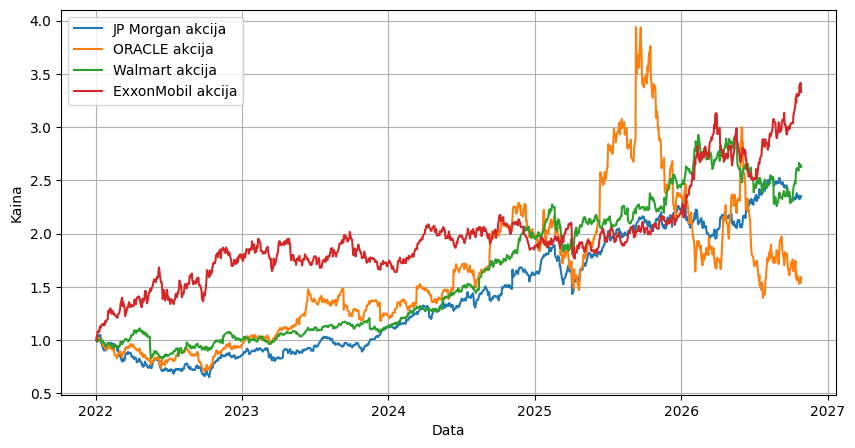

In [ ]:
kainos=df3['Close']
normuotos=kainos/kainos.iloc[0]

fig,ax=plt.subplots(figsize=(10,5))
ax.plot(normuotos['JPM'],label='JP Morgan akcija')
ax.plot(normuotos['ORCL'],label='ORACLE akcija')
ax.plot(normuotos['WMT'],label='Walmart akcija')
ax.plot(normuotos['XOM'],label='ExxonMobil akcija')
ax.set_xlabel('Data')
ax.set_ylabel('Kaina')
ax.grid(True)
ax.legend()
plt.show()


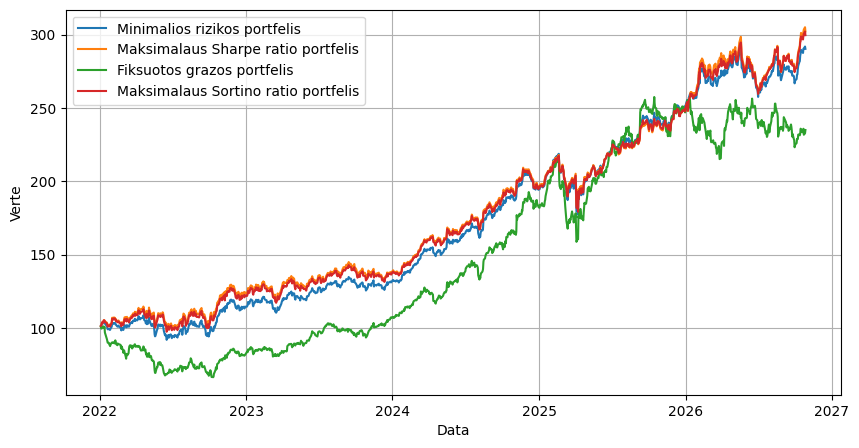

In [ ]:
R=kainos.pct_change().dropna()

def verte(b,R,V0=100):
  r=R @ np.reshape(b,(-1,1))
  return V0*(1+r.iloc[:,0]).cumprod()

B_mvp=verte(min_rizikos_portfelis,R)
B_msr=verte(max_sharpe_portfelis,R)
B_fiks=verte(fiksuotos_grazos_portfelis,R)
B_sortino=verte(MSOR(R.values,0),R)

fig,ax=plt.subplots(figsize=(10,5))
ax.plot(B_mvp,label='Minimalios rizikos portfelis')
ax.plot(B_msr,label='Maksimalaus Sharpe ratio portfelis')
ax.plot(B_fiks,label='Fiksuotos grazos portfelis')
ax.plot(B_sortino,label='Maksimalaus Sortino ratio portfelis')
ax.set_xlabel('Data')
ax.set_ylabel('Verte')
ax.grid(True)
ax.legend()
plt.show()
